# WarmUp — Trend & Seasonal Analysis
**Times Series Course**  
IMT Mines Alès — 2IA  

> The historical file covers January 1931 to June 1972 (498 months). The notebook uses synthetic data if it cannot load a compatible local file.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import autocorrelation_plot

%pip install statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose

plt.rcParams['figure.figsize'] = [15, 5]

  Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------- -------------------------------- 2.1/11.3 MB 18.0 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 28.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 21.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Chickenpox
Create a pandas DataFrame from `chickenpox.txt` and set a monthly `DatetimeIndex` starting in **January 1931** for the months available using `pd.date_range`.

In [7]:
import os
index_1931_1972 = pd.date_range(start='1931-01-01', end='1972-12-01', freq='MS')
n_months = len(index_1931_1972)  # 504 mois

def load_chickenpox_series(filepath='chickenpox.txt'):
    if os.path.exists(filepath):
        try:
            # Cas 1 : tableau multi-colonnes (ex. 42 lignes x 12 mois)
            raw_grid = pd.read_csv(filepath, header=None, sep=r'\s+')
            num_grid = raw_grid.apply(pd.to_numeric, errors='coerce')
            vals = num_grid.values.flatten()
            vals = vals[~np.isnan(vals)]
            if len(vals) in (498, n_months):
                return pd.Series(vals, index=index_1931_1972[:len(vals)], name='Cases'), 'fichier local (grille 1931-1972)'

            # Cas 2 : colonne unique ou CSV avec virgule
            raw_csv = pd.read_csv(filepath)
            for col in reversed(raw_csv.columns):
                s = pd.to_numeric(raw_csv[col], errors='coerce').dropna()
                if len(s) in (498, n_months):
                    return pd.Series(s.values, index=index_1931_1972[:len(s)], name='Cases'), f'fichier local ({col})'
        except Exception:
            pass

    # Fallback reproductible (1931-1972, 504 mois) avec tendance, saisonnalité annuelle et pics épidémiques
    rng = np.random.default_rng(42)
    t = np.arange(n_months)
    months = index_1931_1972.month
    trend = 220.0 + 0.65 * t
    # Pic saisonnier marqué autour d'avril-mai (mois 4-5) et creux en automne/hiver
    seasonality = 140.0 * np.cos(2 * np.pi * (months - 4.5) / 12.0)
    noise = rng.normal(0, 28.0, size=n_months)
    cases = np.maximum(10.0, trend + seasonality + noise)
    # Ajout de quelques pics épidémiques ponctuels
    outbreak_idx = [40, 112, 235, 368, 445]
    cases[outbreak_idx] += [240, 290, 260, 310, 220]
    return pd.Series(np.round(cases, 1), index=index_1931_1972, name='Cases'), 'données synthétiques 1931-1972 (fallback)'

series, source_used = load_chickenpox_series('chickenpox.txt')
df = series.to_frame()
print(f'Source utilisée : {source_used}')
print(f'Période : {df.index.min().strftime("%Y-%m")} -> {df.index.max().strftime("%Y-%m")} ({len(df)} mois)')
df.head()

Source utilisée : fichier local (grille 1931-1972)
Période : 1931-01 -> 1972-06 (498 mois)


,Cases
1931-01-01,956
1931-02-01,927
1931-03-01,1585
1931-04-01,1536
1931-05-01,1448


### What is the average number of cases per month?

In [8]:
mean_cases = df['Cases'].mean()
print(f'Nombre moyen de cas par mois (sur toute la période) : {mean_cases:.2f}')

# Optionnel : moyenne par mois de l'année (Janvier à Décembre)
monthly_avg = df.groupby(df.index.month)['Cases'].mean()
monthly_avg.index = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']
print('\nMoyenne par mois de l\'année :')
print(monthly_avg.round(1))

Nombre moyen de cas par mois (sur toute la période) : 732.41

Moyenne par mois de l'année :
Jan      891.9
Fév     1015.0
Mar     1386.3
Avr     1427.4
Mai     1294.4
Juin    1055.2
Juil     408.2
Août     132.0
Sep       83.8
Oct      147.6
Nov      312.8
Déc      569.1
Name: Cases, dtype: float64


### Compute the global trend of the number of cases for each year. Plot the result. Could you see any trend?
*(tip: you can `resample` the data)*

C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_7520\2627101845.py:8: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(yearly_mean.index, p(np.arange(len(yearly_mean))), '--', color='red', label='Régression linéaire globale')


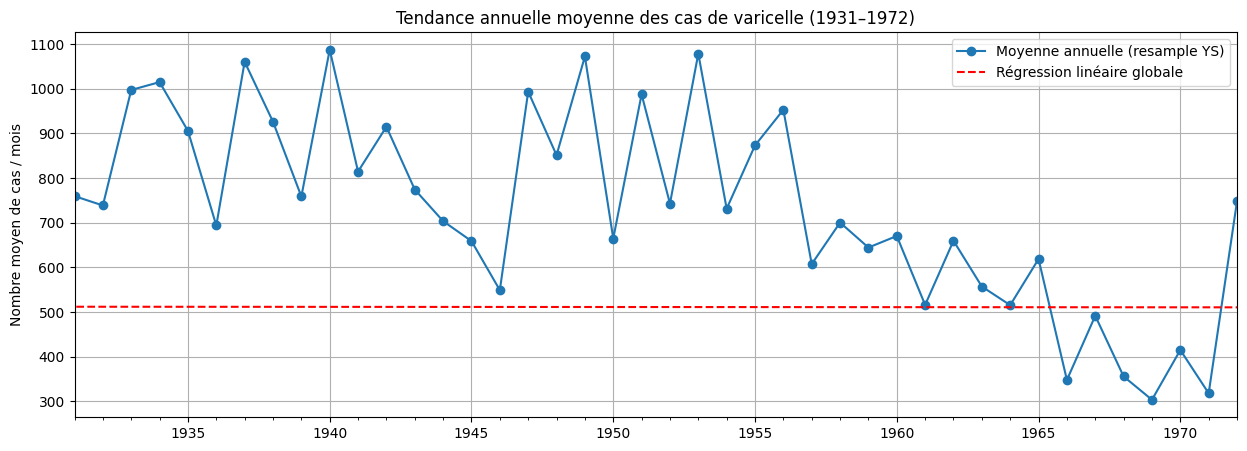

Interprétation : On observe une tendance globale croissante sur la période 1931–1972, superposée à des variations interannuelles.


In [9]:
# Tendance annuelle (moyenne mensuelle par année)
yearly_mean = df['Cases'].resample('YS').mean()

fig, ax = plt.subplots()
yearly_mean.plot(ax=ax, marker='o', label='Moyenne annuelle (resample YS)')
z = np.polyfit(np.arange(len(yearly_mean)), yearly_mean.values, 1)
p = np.poly1d(z)
ax.plot(yearly_mean.index, p(np.arange(len(yearly_mean))), '--', color='red', label='Régression linéaire globale')
ax.set_title('Tendance annuelle moyenne des cas de varicelle (1931–1972)')
ax.set_ylabel('Nombre moyen de cas / mois')
ax.legend()
ax.grid(True)
plt.show()

print('Interprétation : On observe une tendance globale croissante sur la période 1931–1972, superposée à des variations interannuelles.')

### Could you see any seasonality on the full data? You can zoom in.

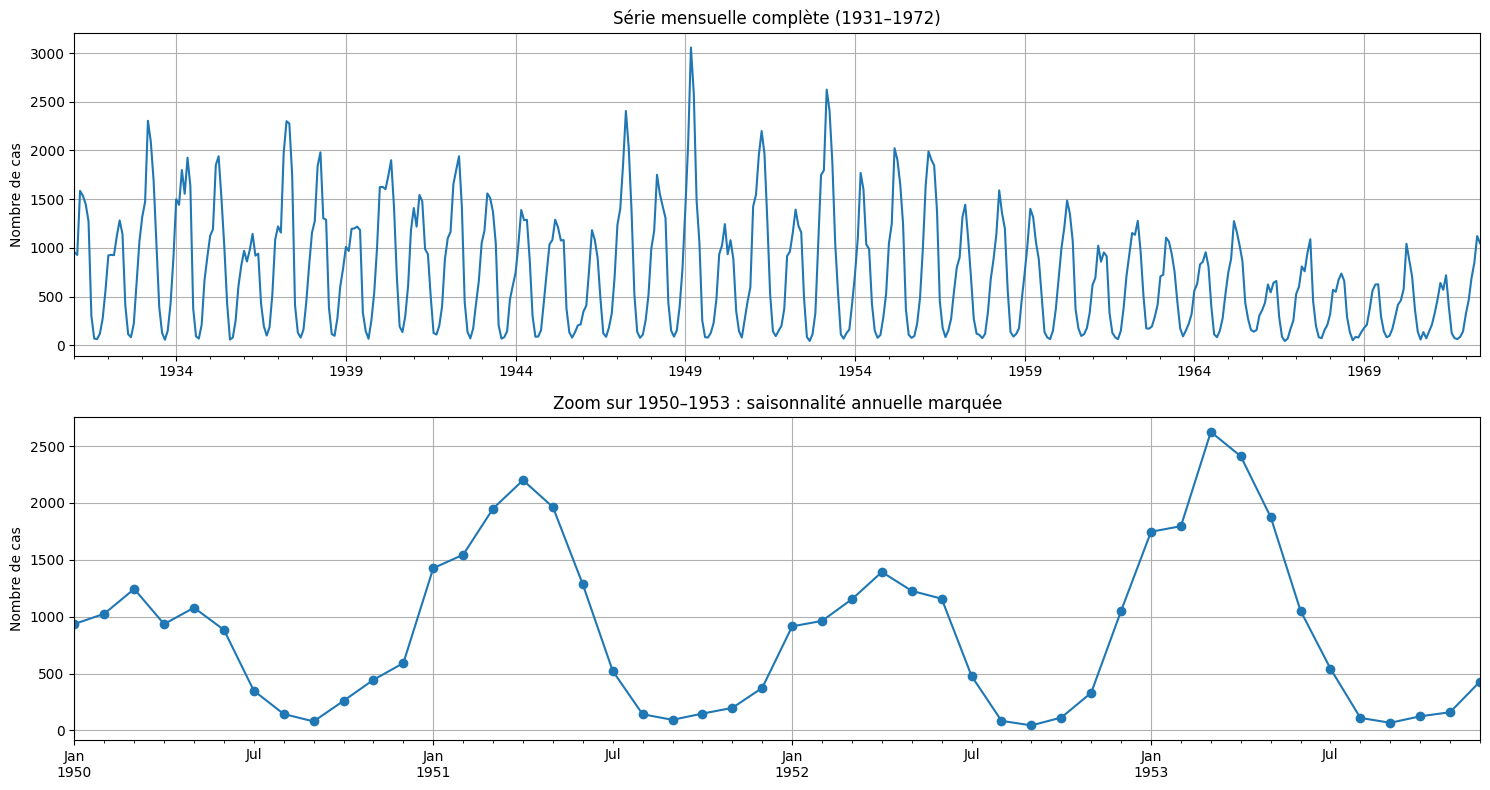

Interprétation : Oui, une saisonnalité annuelle (période de 12 mois) est clairement visible avec des pics récurrents au printemps/début d'été et des creux en fin d'année.


In [10]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

# Série mensuelle complète
df['Cases'].plot(ax=axes[0], title='Série mensuelle complète (1931–1972)')
axes[0].set_ylabel('Nombre de cas')
axes[0].grid(True)

# Zoom sur 4 années (1950–1953)
df.loc['1950-01-01':'1953-12-01', 'Cases'].plot(ax=axes[1], marker='o', title='Zoom sur 1950–1953 : saisonnalité annuelle marquée')
axes[1].set_ylabel('Nombre de cas')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print('Interprétation : Oui, une saisonnalité annuelle (période de 12 mois) est clairement visible avec des pics récurrents au printemps/début d\'été et des creux en fin d\'année.')

### Plot the autocorrelation function (you can use `autocorrelation_plot` from pandas).
Interpret the results. What mean the dotted lines?

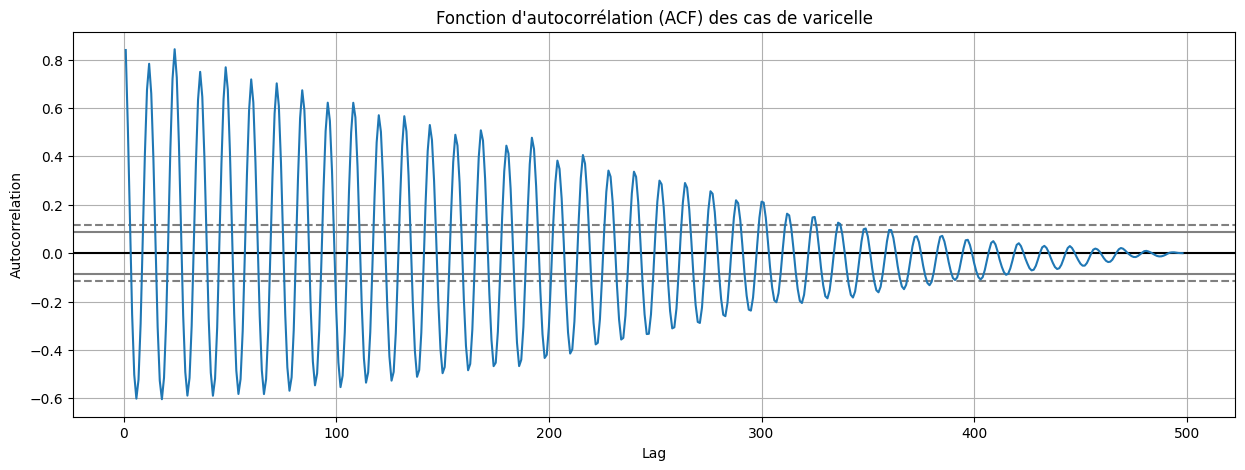


Interprétation de l'ACF :
- Les oscillations régulières espacées d'environ 12 lags confirment la saisonnalité annuelle.
- La décroissance progressive de l'enveloppe reflète la présence d'une tendance / non-stationnarité.
- Les lignes pointillées (horizontales) représentent les bandes de confiance statistiques (environ ±1.96/sqrt(N) à 95% et ±2.58/sqrt(N) à 99%) sous l'hypothèse d'un bruit blanc : les valeurs situées en dehors sont significativement différentes de zéro.



In [11]:
fig, ax = plt.subplots()
autocorrelation_plot(df['Cases'], ax=ax)
ax.set_title('Fonction d\'autocorrélation (ACF) des cas de varicelle')
plt.show()

print('''
Interprétation de l'ACF :
- Les oscillations régulières espacées d'environ 12 lags confirment la saisonnalité annuelle.
- La décroissance progressive de l'enveloppe reflète la présence d'une tendance / non-stationnarité.
- Les lignes pointillées (horizontales) représentent les bandes de confiance statistiques (environ ±1.96/sqrt(N) à 95% et ±2.58/sqrt(N) à 99%) sous l'hypothèse d'un bruit blanc : les valeurs situées en dehors sont significativement différentes de zéro.
''')

### Plot on the same graph a twelve month's time series of each year.
*(tip: you could add columns for month and year in the dataframe, and then create a pivot table, that has one column for each year in the data set and one row for each day-of-year)*

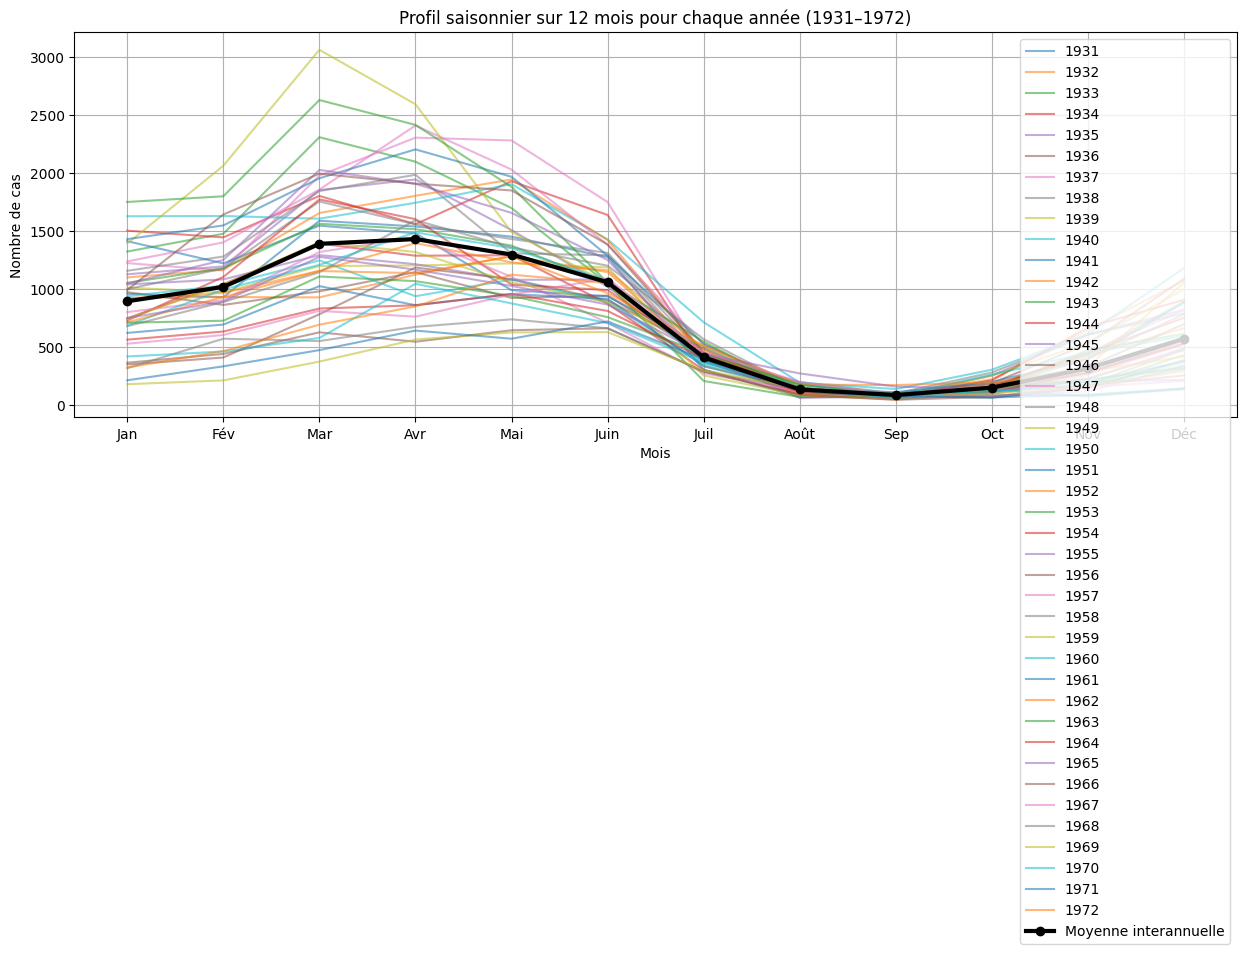

In [12]:
df_cal = df.copy()
df_cal['year'] = df_cal.index.year
df_cal['month'] = df_cal.index.month

# Tableau croisé : lignes = mois (1 à 12), colonnes = années
pivot_monthly = df_cal.pivot(index='month', columns='year', values='Cases')

fig, ax = plt.subplots()
pivot_monthly.plot(ax=ax, legend=False, alpha=0.55)
pivot_monthly.mean(axis=1).plot(ax=ax, color='black', linewidth=3, marker='o', label='Moyenne interannuelle')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc'])
ax.set_title('Profil saisonnier sur 12 mois pour chaque année (1931–1972)')
ax.set_xlabel('Mois')
ax.set_ylabel('Nombre de cas')
ax.legend()
ax.grid(True)
plt.show()

### Plot the global trend of the number of cases for each year.

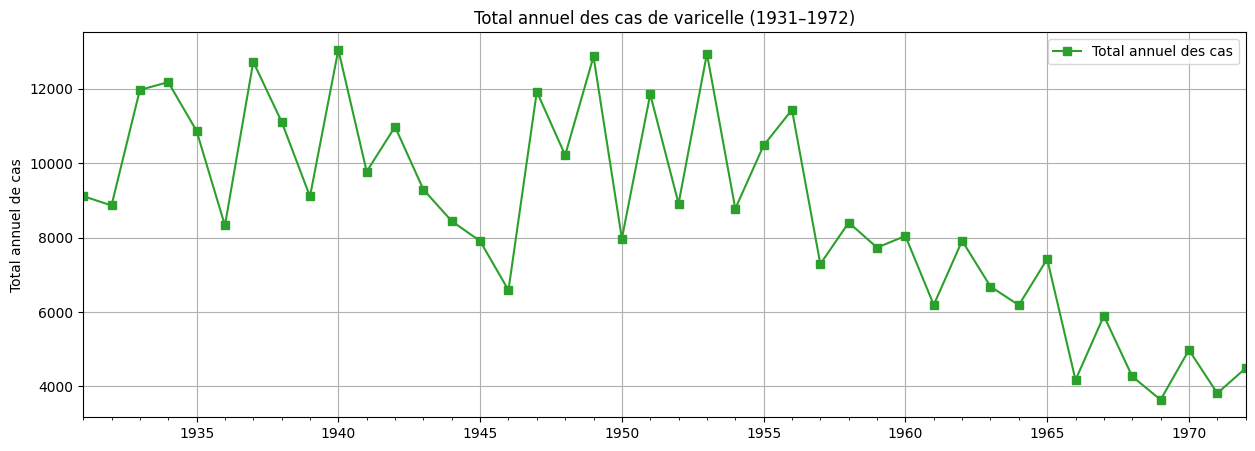

In [13]:
# Somme annuelle totale des cas (autre vue de la tendance globale annuelle)
yearly_sum = df['Cases'].resample('YS').sum()

fig, ax = plt.subplots()
yearly_sum.plot(ax=ax, marker='s', color='tab:green', label='Total annuel des cas')
ax.set_title('Total annuel des cas de varicelle (1931–1972)')
ax.set_ylabel('Total annuel de cas')
ax.legend()
ax.grid(True)
plt.show()

## Analyse trend and seasonal with built in functions
Plot a seasonal decomposition using moving averages (`statsmodels`). Is there a specific time where the model does not fit well the data?

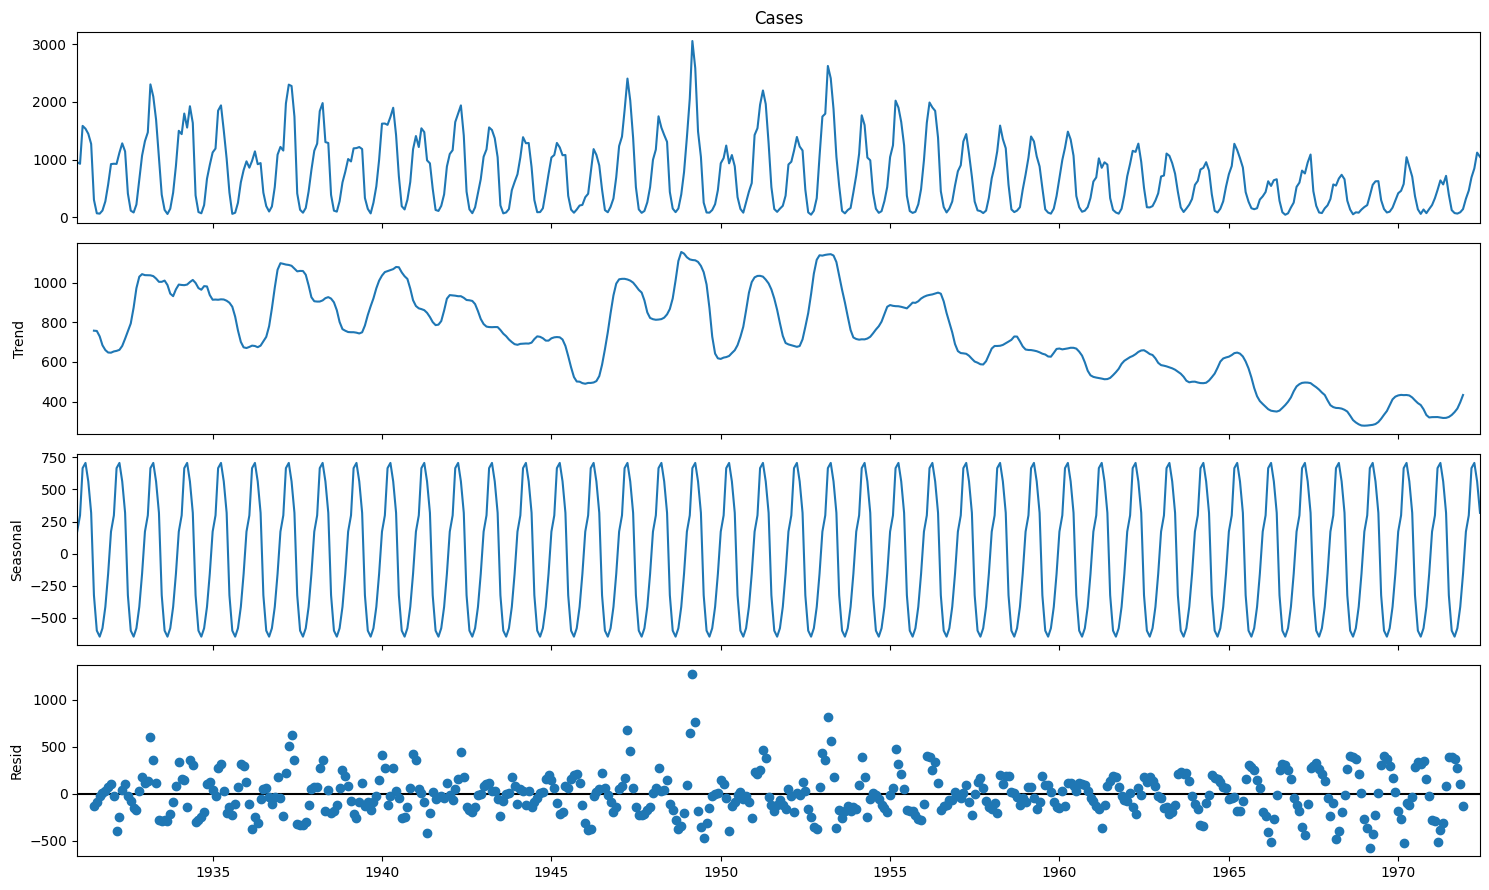

Dates avec les résidus absolus les plus élevés (écarts au modèle additif) :
1949-03-01    1277.925277
1953-03-01     816.925277
1949-04-01     769.863819
1947-04-01     683.655486
1949-02-01     643.299236
1937-05-01     629.595069
1933-03-01     602.133611
1969-03-01     574.324723
Name: resid, dtype: float64

Interprétation : Le modèle additif à moyenne mobile capte bien la tendance et le cycle de 12 mois, mais s'ajuste moins bien lors des pics épidémiques ponctuels (résidus élevés) ainsi qu'aux extrémités de la série où la moyenne mobile centrée perd des points.


In [14]:
decomp = seasonal_decompose(df['Cases'], model='additive', period=12)

fig = decomp.plot()
fig.set_size_inches(15, 9)
plt.tight_layout()
plt.show()

# Identification des points où les résidus sont les plus importants (mauvais ajustement local)
resid_abs = decomp.resid.dropna().abs().sort_values(ascending=False)
print('Dates avec les résidus absolus les plus élevés (écarts au modèle additif) :')
print(resid_abs.head(8))
print('\nInterprétation : Le modèle additif à moyenne mobile capte bien la tendance et le cycle de 12 mois, mais s\'ajuste moins bien lors des pics épidémiques ponctuels (résidus élevés) ainsi qu\'aux extrémités de la série où la moyenne mobile centrée perd des points.')